# Observer Heliocentric frame effect on SNe Ia magnitude and redshift

This notebook provides an example usage of the zcmb_to_zhel and magobs_to_magobshel functions in order to apply the effect of the CMB dipole to the cosmological redshifts and magnitudes.

## Import Libraries

In [ ]:
import matplotlib.pyplot as plt
import skysurvey
from skysurvey.tools import velocities as vpec
from astropy.cosmology import Planck18

## Set plots colour chart

In [15]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

BLUE = '#1F487E'
RED = '#A31621'
BEIGE = 'beige'

cmap = LinearSegmentedColormap.from_list(
    'custom_red_beige_blue',
    [BLUE, BEIGE, RED]
)

norm = TwoSlopeNorm(
    vmin=-0.3,
    vcenter=0.0,
    vmax=0.3
)

## Set standardisation parameters

In [16]:
z_max = 0.2
alpha = -0.15 
beta = 3
mabs = -19.3
sigma_int = 0.0

## Define SNe Ia model

In [17]:
model = {'redshift': {'func': 'draw_redshift', 'kwargs': {'zmax': z_max}, 'as': 'z'},
 'x1': {'func': skysurvey.target.snia.SNeIaStretch.nicolas2021,
        'kwargs': {}},
 'c': {'func': skysurvey.target.snia.SNeIaColor.intrinsic_and_dust,
       'kwargs': {}},
 'magabs': {'func': skysurvey.target.snia.SNeIaMagnitude.tripp1998,
            'kwargs': {'x1': '@x1', 'c': '@c', 'mabs': mabs, 'alpha': alpha, 'beta': beta, 'sigmaint': sigma_int}},
 'magobs': {'func': 'magabs_to_magobs',
            'kwargs': {'z': '@z', 'magabs': '@magabs'}},
 'radec': {'func': skysurvey.target.random_radec,
           'kwargs': {},
           'as': ['ra', 'dec']},
 'zhel': {'func': vpec.zcmb_to_zhel,
             'kwargs': {'zcmb': '@z', 'ra': '@ra', 'dec': '@dec'},
             },
 'magobshel': {'func': vpec.magobs_to_magobshel,
            'kwargs': {'magobs': '@magobs', 'z': '@z', 'zhel': '@zhel'}},}

## Draw SNe Ia data

In [18]:
sn = skysurvey.SNeIa.from_draw(size=1000, set_amplitude=False, cosmology=Planck18, model=model)

In [19]:
data = sn.data

In [20]:
data.head()

,z,x1,c,t0,ra,dec,magabs,zhel,magobs,magobshel,template
0,0.18215,-0.775,-0.059,56084.335938,197.387390,-48.129486,-19.360750,0.181178,20.440178,20.438391,salt2
1,0.17285,-0.225,0.010,56054.593750,42.982105,-15.488763,-19.236250,0.173597,20.438881,20.440264,salt2
2,0.13795,0.455,0.072,56057.109375,195.835098,0.028112,-19.152250,0.136719,19.986717,19.984367,salt2
3,0.17025,-1.580,-0.092,56089.003906,106.229973,32.630360,-19.339001,0.169772,20.299839,20.298952,salt2
4,0.13875,0.535,0.217,56004.675781,127.820801,-22.708622,-18.729250,0.137701,20.423363,20.421362,salt2


## Plot redshift difference

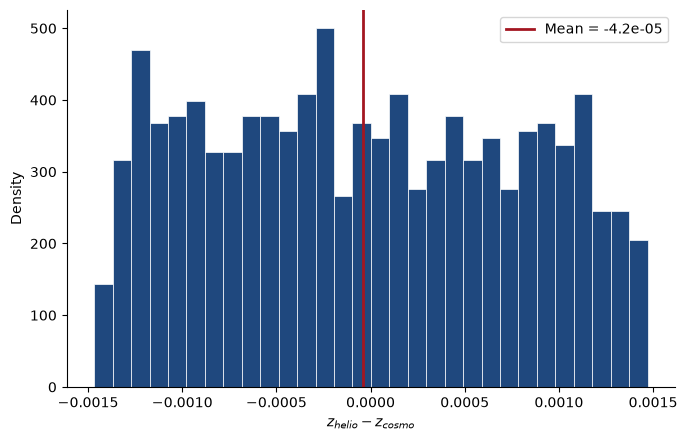

In [21]:
dz = data['zhel'] - data['z']

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.hist(dz, bins=30, density=True, color=BLUE, edgecolor='white', linewidth=0.5)
ax.axvline(dz.mean(), color=RED, lw=2, ls='-', label=rf'Mean = {dz.mean():.2g}')

ax.set_xlabel(r'$z_{helio}-z_{cosmo}$')
ax.set_ylabel('Density')
ax.legend(frameon=True)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## Plot magnitude difference due to the redshift

In [22]:
# residuals = data['magobs'] - Planck18.distmod(data['z']).value - mabs - alpha*data['x1'] - beta*data['c']
residuals_helio = data['magobs'] - Planck18.distmod(data['zhel']).value - mabs- alpha*data['x1'] - beta*data['c']
residuals_helio_mag_correc =  data['magobshel'] - Planck18.distmod(data['zhel']).value - mabs- alpha*data['x1'] - beta*data['c']

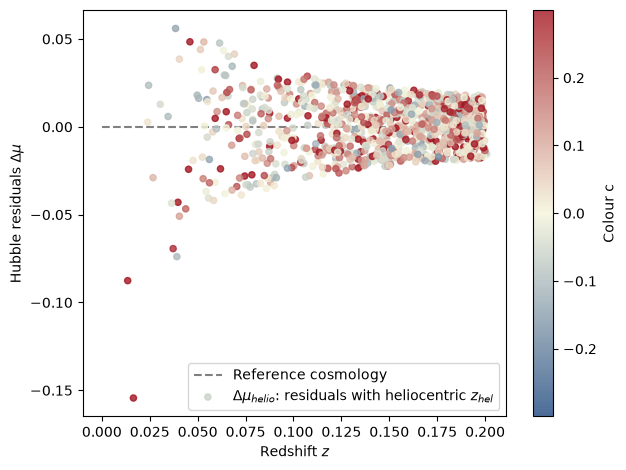

In [33]:
fig, ax = plt.subplots()

ax.hlines(0, 0, data['z'].max(), ls='--', color='gray', zorder=0, label='Reference cosmology')
sc = ax.scatter(data['zhel'], residuals_helio, c=data['c'], norm=norm, cmap=cmap,
                alpha=0.8, label=r'$\Delta \mu_{helio}$: residuals with heliocentric $z_{hel}$', s=20)

ax.set_xlabel(r'Redshift $z$')
ax.set_ylabel(r'Hubble residuals $\Delta \mu$')
ax.legend()

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Colour c')

fig.tight_layout()
plt.show()

## Plot magnitude difference due to the magnitude correction

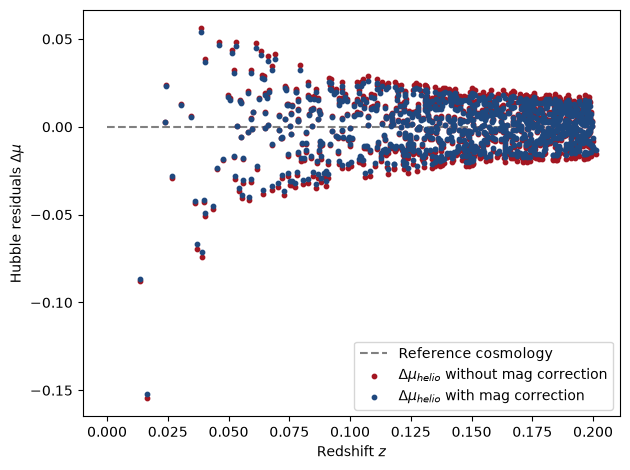

In [31]:
fig, ax = plt.subplots()

ax.hlines(0, 0, data['z'].max(), ls='--', color='gray', zorder=0, label='Reference cosmology')

ax.scatter(data['zhel'], residuals_helio, c=RED, s=10, label=r'$\Delta \mu_{helio}$ without mag correction')
ax.scatter(data['zhel'], residuals_helio_mag_correc, c=BLUE, s=10, label=r'$\Delta \mu_{helio}$ with mag correction')

ax.set_xlabel(r'Redshift $z$')
ax.set_ylabel(r'Hubble residuals $\Delta \mu$')
ax.legend()

fig.tight_layout()
plt.show()



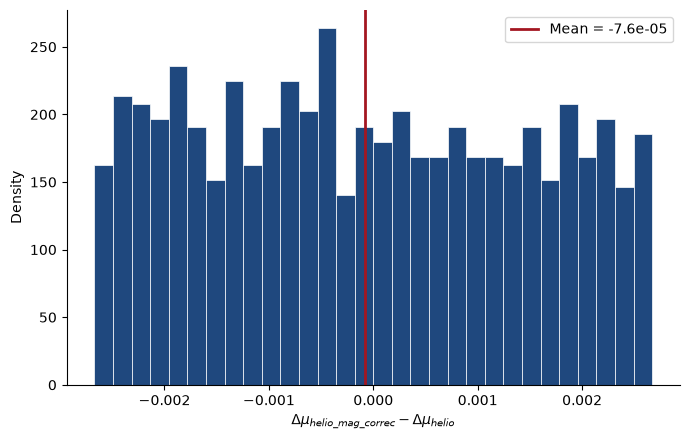

In [29]:
dmag = residuals_helio_mag_correc-residuals_helio

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.hist(dmag, bins=30, density=True, color=BLUE, edgecolor='white', linewidth=0.5)
ax.axvline(dmag.mean(), color=RED, lw=2, ls='-', label=rf'Mean = {dmag.mean():.2g}')

ax.set_xlabel(r'$\Delta \mu_{helio\_mag\_correc} - \Delta \mu_{helio}$')
ax.set_ylabel('Density')
ax.legend(frameon=True)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()